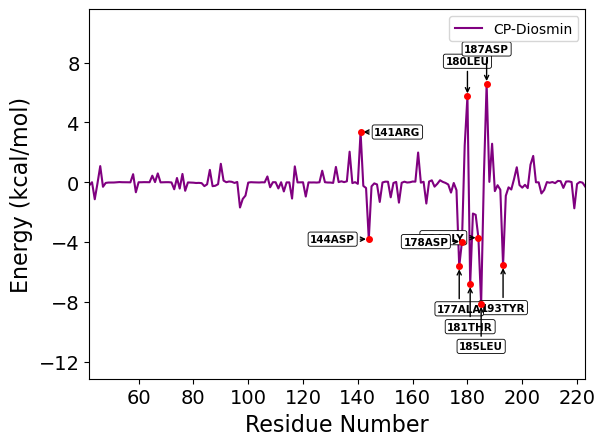

In [3]:
import matplotlib.pyplot as plt
import numpy as np

# ---------- USER INPUT SECTION ----------
energy_file = '42-energyMapIn.dat'     # Path to energy file
pdb_file = 'Protein.pdb'               # Path to PDB file

# Manual override for axis limits (set to None to auto)
x_limits = None  # Example: (0, 180)
y_limits = None  # Example: (-10, 12)
# ----------------------------------------

# Function to read residue numbers and amino acid names from PDB file
def get_residue_info(pdb_file):
    residue_info = {}  # Key: residue number, Value: residue name
    with open(pdb_file, 'r') as f:
        for line in f:
            if line.startswith("ATOM"):
                res_num = int(line[22:26].strip())
                res_name = line[17:20].strip()
                if res_num not in residue_info:
                    residue_info[res_num] = res_name
    return residue_info

# Function to read energy values (excluding last total row)
def read_energy_file(file_path):
    data = np.genfromtxt(file_path)
    if data.ndim == 1:
        data = data.reshape(-1, 2)
    data = data[:-1]  # Exclude last row (total)
    energy = data[:, 1]
    return energy

# Read data
residue_info = get_residue_info(pdb_file)
residue_numbers = sorted(residue_info.keys())
energy_values = read_energy_file(energy_file)

# Ensure residue numbers and energy values align
if len(residue_numbers) != len(energy_values):
    raise ValueError(f"Mismatch: {len(residue_numbers)} residues in PDB vs {len(energy_values)} energy values")

# Plotting
fig, ax = plt.subplots()

# Plot energy line
ax.plot(residue_numbers, energy_values, label='CP-Diosmin', color='purple')

# X and Y axis limits: manual or automatic
if x_limits:
    ax.set_xlim(*x_limits)
else:
    ax.set_xlim(min(residue_numbers), max(residue_numbers))

if y_limits:
    ax.set_ylim(*y_limits)
else:
    y_min = np.min(energy_values)
    y_max = np.max(energy_values)
    ax.set_ylim(y_min - 5, y_max + 5)

# Axis labels and ticks
ax.set_xlabel('Residue Number', fontsize=16)
ax.set_ylabel('Energy (kcal/mol)', fontsize=16)
ax.tick_params(axis='both', which='major', labelsize=14)
ax.xaxis.set_major_locator(plt.MaxNLocator(10))
ax.yaxis.set_major_locator(plt.MaxNLocator(8))

# Label top 10 peaks with amino acid names (bold, compact, smart placement)
top_indices = np.argsort(np.abs(energy_values))[-10:]
for idx in top_indices:
    res_num = residue_numbers[idx]
    res_name = residue_info[res_num]
    energy = energy_values[idx]
    label = f"{res_num}{res_name.upper()}"

    # Plot red dot at the peak
    ax.plot(res_num, energy, 'o', color='red', markersize=4, zorder=5)

    # Decide direction: vertical if peak is tall, else horizontal
    vertical = abs(energy) > 4  # tall peak → vertical label
    if vertical:
        # Arrow and label placed vertically (up/down)
        y_offset = 2 if energy > 0 else -2.5
        label_y = energy + y_offset
        ha, va = 'center', 'bottom' if energy > 0 else 'top'
        ax.annotate(label,
                    xy=(res_num, energy), xycoords='data',
                    xytext=(res_num, label_y), textcoords='data',
                    fontsize=7.5, fontweight='bold',
                    ha=ha, va=va,
                    bbox=dict(boxstyle='round,pad=0.2', fc='white', ec='black', lw=0.6),
                    arrowprops=dict(arrowstyle='->', color='black', lw=1))
    else:
        # Arrow and label placed horizontally (side)
        x_offset = 5 if energy > 0 else -5
        label_x = res_num + x_offset
        ha = 'left' if energy > 0 else 'right'
        ax.annotate(label,
                    xy=(res_num, energy), xycoords='data',
                    xytext=(label_x, energy), textcoords='data',
                    fontsize=7.5, fontweight='bold',
                    ha=ha, va='center',
                    bbox=dict(boxstyle='round,pad=0.2', fc='white', ec='black', lw=0.6),
                    arrowprops=dict(arrowstyle='->', color='black', lw=1))

# Final legend and save
ax.legend(fontsize=10)
plt.savefig('CP-Diosmin_per_residue_contribution.svg', format='svg', bbox_inches='tight')
plt.savefig('CP-Diosmin_per_residue_contribution.jpg', format='jpg', dpi=300, bbox_inches='tight')
plt.show()
